# 09 · Fake accounts (E4)

**Experiment E4 of the project plan:** can fake accounts push a group up the suggestions, and does rule R9 stop them?

On BOING, an account is a wallet and a username, so making many accounts is cheap (assumption 2 of the report). Someone who wants their group to be seen
can make fake accounts that join it *together with the most popular groups*. "Also joined" and the AI model then link the group to those popular
groups, and suggest it to their members. Rule R9 is the defence. It acts in `br.group_stats()`, where every statistic about other members is made,
and it reads only public data:

- **level bar L**: only accounts at level L or more count (L = 1, 3 or 5; L = 1 means everyone), and each account counts once;
- **burst rule**: the joins of *young* accounts (created in the last 30 days) count as a fraction `burst_w` of a member.

What this notebook does:

1. adds 0 to 200 fake accounts (0% to 10% of the 2,000 members) to a copy of the data, in memory: the files in `data/sim_v1` are never changed;
2. chooses L and `burst_w` on the practice quiz, with a rule fixed in advance;
3. measures on the test, for real members only: how often the target group is shown, where it ranks, how many places each fake account buys,
   and accuracy (NDCG@5), with R9 off and on;
4. measures what R9 costs honest newcomers when there is no attack;
5. tries fake accounts that also post and like, against the list every member sees by default (section 10);
6. recommends L and `burst_w`, and what R9 must act on.

Run notebooks 01, 02 and 06 first. The code shared by all notebooks is in `boingrec.py`, in this folder. This notebook takes about 10 minutes.

## 0 · Settings and data

In [1]:
# Colab only: upload sim_v1.zip and sim_v1_split.zip (from notebooks 01 and 02) and boingrec.py (from the notebooks folder),
# all three at once. Locally this cell does nothing.
import sys, zipfile
from pathlib import Path
if 'google.colab' in sys.modules and not Path('boingrec.py').exists():
    from google.colab import files
    for fname in files.upload():
        if fname.endswith('.zip'):
            with zipfile.ZipFile(fname) as z:
                z.extractall('data')

In [2]:
import hashlib
import json
import os
from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from joblib import Parallel, delayed     # runs several recommend() calls at once (joblib comes with scikit-learn)
import boingrec as br

SEED, K = br.SEED, br.K                 # 0 and 5, the same in every notebook
br.use_style()
cfg = br.Config()                       # the proposed design of notebook 06, with R9 off (L = 1, burst_w = 1)

KS = [0, 10, 20, 50, 100, 200]          # numbers of fake accounts: 0 to 10% of the 2,000 members
LEVELS = [1, 3, 5]                      # level bars to try (the report's values; 1 = everyone counts)
WEIGHTS = [1.0, 0.5, 0.25, 0.1, 0.0]    # burst weights to try (1 = no burst rule; 0 = young accounts don't count at all)
RULE_K = 100                            # the choice rule must hold up to 100 fake accounts (5%): section 4
FAKE_DAYS = 7                           # fresh fake accounts were created in the last 7 days...
BURST_DAYS = 2                          # ...and all their joins happen in the last 2 days (one burst)

vis = br.load_visible()                 # what a recommender may read: no test file, no hidden column (no is_fake)
ans = br.load_answers()                 # the answer key: only the scoring code reads it
tested = sorted(ans.test.user_id.unique())
gids = br.group_ids(vis)
name = vis.groups.set_index('group_id').name
created = vis.groups.set_index('group_id').created_day
users = vis.users.set_index('user_id')
discover = br.discover_groups(vis.groups)
CLUSTERS = br.topic_clusters(vis)       # public topic clusters (group texts only: fake accounts cannot change them), made once
N_MEMBERS = len(vis.users)
print(f'{N_MEMBERS} members, {len(gids)} groups ({len(discover)} on Discover), {len(tested)} members to test. '
      f'Fake accounts in the data: {int(ans.user_is_fake.sum())} (so we add them below).')

2000 members, 150 groups (129 on Discover), 1406 members to test. Fake accounts in the data: 0 (so we add them below).


## 1 · Rule R9: whose joins count

`br.group_stats()` builds the table X of who is in which group, and from it X<sup>T</sup>X: how many members each pair of groups shares, with the group
sizes on its diagonal. "Also joined", the AI model, the group sizes (and so which groups count as *small*) all come from that one table.
R9 changes what goes into X:

- an account below level L is left out (it still gets its own suggestions; it just doesn't shape other people's);
- a young account counts as `burst_w` of a member: it adds `burst_w` (not 1) to each of its groups' sizes and to each pair count.

Both rules use only public columns (`level`, `created_day`). The recommender cannot read `is_fake`: `br.load_visible()` never loads it.
Here is who the rules touch among the real members, before any attack:

In [3]:
real = users[users.suspended == 0]
young = real.created_day > br.TODAY - cfg.young_days
mem = vis.train[vis.train.user_id.isin(real.index)]
mem_level = real.level.reindex(mem.user_id).to_numpy()
mem_young = young.reindex(mem.user_id).to_numpy()
rows = {}
for L in LEVELS[1:]:
    below = real.level < L
    rows[f'level bar L = {L}: accounts below level {L} do not count'] = {
        'accounts': int(below.sum()), 'of which young': int((below & young).sum()),
        'their memberships': int((mem_level < L).sum()), 'share of all memberships': float((mem_level < L).mean())}
rows[f'burst rule: accounts created in the last {cfg.young_days} days count less'] = {
    'accounts': int(young.sum()), 'of which young': int(young.sum()),
    'their memberships': int(mem_young.sum()), 'share of all memberships': float(mem_young.mean())}
affected = pd.DataFrame(rows).T
affected[['accounts', 'of which young', 'their memberships']] = affected[['accounts', 'of which young', 'their memberships']].astype(int)
print(f'{len(real)} accounts that are not suspended hold {len(mem)} training memberships; {int(young.sum())} accounts are young.')
affected.round(3)

1983 accounts that are not suspended hold 6367 training memberships; 300 accounts are young.


,accounts,of which young,their memberships,share of all memberships
level bar L = 3: accounts below level 3 do not count,86,86,74,0.012
level bar L = 5: accounts below level 5 do not count,229,223,200,0.031
burst rule: accounts created in the last 30 days count less,300,300,282,0.044


Every account below level 3 is a young one: in this community, low levels simply mean *new*. Young accounts hold few memberships (at most 2 each,
and a third of them have none yet), about 4% of all of them.

How hard is it to get past the level bar? In BOING, level 3 takes 125 XP and level 5 takes 350 XP. The daily caps allow up to 100 XP per game
per day, so both can be reached in one day of play. The level bar slows an attacker down but does not stop a determined one.
An account's age cannot be sped up: that is why the burst rule exists.

## 2 · The attack

**The bait:** the three biggest groups on Discover (anyone can see the member counts). **The target:** the attacker's own group, small, new and open.
To avoid picking a convenient one, we take it by a fixed rule: the newest open group on Discover that has exactly one member (its creator) and is
about none of the bait's topics, so that any climb is the attack's doing. (The topics are read here only to pick the target; the recommender never sees them.)

In [4]:
def popular_groups(v, n=3):
    # The attacker's bait: the n biggest groups on Discover, from the member counts anyone can see
    s = br.group_sizes(v)[br.discover_groups(v.groups)]
    return s.sort_values(ascending=False, kind='stable').index[:n].to_numpy()

POPULAR = popular_groups(vis)
size = br.group_sizes(vis)
bait_topics = set(ans.group_topic[POPULAR])               # scoring side only: to pick a target unrelated to the bait
eligible = [g for g in discover if created[g] > br.TODAY - br.NEW_DAYS and size[g] == 1 and ans.group_topic[g] not in bait_topics]
TARGET = max(eligible, key=lambda g: (created[g], g))     # the newest one
NEW_GROUPS = [g for g in discover if created[g] > br.TODAY - br.NEW_DAYS]   # the new groups on Discover (created in the last 30 days)
pd.DataFrame({'role': ['bait'] * len(POPULAR) + ['TARGET'], 'group': name[list(POPULAR) + [TARGET]].to_numpy(),
              'members': size[list(POPULAR) + [TARGET]].to_numpy(), 'days old': (br.TODAY - created[list(POPULAR) + [TARGET]]).to_numpy(),
              'topic (hidden)': ans.group_topic[list(POPULAR) + [TARGET]].to_numpy()},
             index=pd.Index(list(POPULAR) + [TARGET], name='group_id'))

,role,group,members,days old,topic (hidden)
group_id,,,,,
10,bait,Weightlifting for beginners,295,365,fitness
4,bait,Finals countdown,286,365,exam_prep
7,bait,Korean conversation club,275,365,languages
149,TARGET,Calculus problem of the day,1,4,maths


**The fake accounts.** Each one has a public profile, no friends, no posts, no likes and no chosen topics. It joins the target and 1 to 3 of the bait
groups, all in the last 2 days (one burst). The plan's attack is **A**: accounts made in the last week, at level 1 or 2. Each rule of R9 can be dodged
at a price, so we also try three smarter attackers, each paying one price or both:

| Attacker | Accounts made | Level | Which rule sees them |
|---|---|---|---|
| **A** (the plan's) | in the last 7 days | 1–2 | both: below the level bar, and young |
| **B** levelled up | in the last 7 days | 5–6 (about a day of play each) | only the burst rule |
| **C** aged | 31–37 days ago, then left waiting | 1–2 | only the level bar |
| **D** aged and levelled up | 31–37 days ago | 5–6 | neither |

The same seed gives the same 200 accounts every time; *k* fake accounts are the first *k* of them, and the four attackers differ only in age and level.
They are marked fake on the scoring side only (`fake_ids`); they never get suggestions.

In [5]:
ATTACKERS = {   # label, level range, extra age in days (0 = made in the last 7 days; 31 = made 31 to 37 days ago)
    'fresh':    {'label': 'A · New accounts, level 1-2', 'levels': (1, 2), 'age': 0},
    'levelled': {'label': 'B · New accounts, levelled up to 5-6', 'levels': (5, 6), 'age': 0},
    'aged':     {'label': 'C · A month old, level 1-2', 'levels': (1, 2), 'age': 31},
    'both':     {'label': 'D · A month old and levelled up', 'levels': (5, 6), 'age': 31},
}
MAX_K = max(KS)


def add_fake_accounts(v, k, attacker='fresh', target=None, popular=None, seed=SEED):
    # A copy of the Visible v with k fake accounts added (v itself is not changed). Returns (copy, fake ids).
    # The copy has exactly v's columns: no is_fake anywhere. The 200 accounts are drawn the same way for every k and
    # every attacker (same seed, same draws), and the first k are kept.
    target = TARGET if target is None else target
    popular = popular_groups(v) if popular is None else np.asarray(popular)
    a = ATTACKERS[attacker]
    rng = np.random.default_rng(seed)
    ids = np.arange(int(v.users.user_id.max()) + 1, int(v.users.user_id.max()) + 1 + MAX_K)
    days_old = a['age'] + rng.integers(0, FAKE_DAYS, MAX_K)
    level = a['levels'][0] + rng.integers(0, a['levels'][1] - a['levels'][0] + 1, MAX_K)
    n_bait = rng.integers(1, 4, MAX_K)                       # 1 to 3 bait groups each
    rows = []
    for i in range(MAX_K):
        for g in [target, *rng.choice(popular, size=n_bait[i], replace=False)]:
            burst_day = int(rng.integers(br.TODAY - BURST_DAYS + 1, br.TODAY + 1))
            rows.append((ids[i], int(g), max(br.TODAY - int(days_old[i]), burst_day)))
    fakes = pd.DataFrame({'user_id': ids, 'created_day': br.TODAY - days_old, 'level': level,
                          'privacy': 'public', 'suspended': 0})[list(v.users.columns)].iloc[:k]
    joins = pd.DataFrame(rows, columns=['user_id', 'group_id', 'joined_day'])
    joins = joins[joins.user_id.isin(fakes.user_id)][list(v.train.columns)]
    attacked = replace(v, users=pd.concat([v.users, fakes], ignore_index=True),
                       train=pd.concat([v.train, joins], ignore_index=True))
    return attacked, fakes.user_id.to_numpy()


example, fake_ids = add_fake_accounts(vis, 3)
print('Columns the recommender sees for users:', list(example.users.columns))
example.train[example.train.user_id.isin(fake_ids)].merge(example.users, on='user_id').assign(group=lambda d: d.group_id.map(name))

Columns the recommender sees for users: ['user_id', 'created_day', 'level', 'privacy', 'suspended']


,user_id,group_id,joined_day,created_day,level,privacy,suspended,group
0,2001,149,364,360,1,public,0,Calculus problem of the day
1,2001,10,364,360,1,public,0,Weightlifting for beginners
2,2001,7,364,360,1,public,0,Korean conversation club
3,2001,4,365,360,1,public,0,Finals countdown
4,2002,149,365,361,1,public,0,Calculus problem of the day
5,2002,4,364,361,1,public,0,Finals countdown
6,2003,149,365,362,1,public,0,Calculus problem of the day
7,2003,7,365,362,1,public,0,Korean conversation club
8,2003,10,365,362,1,public,0,Weightlifting for beginners
9,2003,4,364,362,1,public,0,Finals countdown


## 3 · What we measure

For the real members only (the 1,406 tested members, served together as in notebook 06; the fake accounts get no lists):

- **target exposure**: how many members' lists of 5 contain the target;
- **average rank**: where the scoring step (the hybrid, before re-ranking) puts the target in each member's ranking of all the groups they may be
  shown (1 = first; about 125 candidates each), averaged over the members who may be shown it;
- **places gained per fake account**: (average rank with no attack − average rank with *k* fakes) / *k*: the plan's robustness metric for R9;
- **NDCG@5** and the hit rate on the hidden memberships, as in every notebook;
- **slots for honest newcomers**: slots that go to new or small groups other than the target. An attack that takes them is stealing fair exposure.

Group sizes for the exposure measures come from the real community, so the yardstick does not move with the attack or the defence.

**Two shortcuts keep the notebook fast** (each `recommend()` call takes several seconds, and there are hundreds of runs):

- *Shared runs.* The suggestions depend on the attack only through the statistics `group_stats()` makes. When two runs have exactly the same
  statistics (for example: a defence keeps the fake accounts out completely, so the statistics are those with no attack; or R9 is off, so the four
  attackers, who differ only in age and level, look the same), they share one `recommend()` call. A fingerprint of every number `recommend()` reads
  about other members decides this.
- *Several at once.* The remaining calls run 4 at a time on the computer's cores (the `joblib` library). Every call is deterministic, so the order
  does not matter.

Section 11 checks that both shortcuts give exactly the rows a plain run gives.

In [6]:
def target_ranks(v, user_ids, c, stats, target=TARGET):
    # The target's place in each member's ranking by the hybrid score (1 = first), for the members who may be shown it.
    # Ties: the smaller group id first, as in br.top_k.
    scores = br.hybrid_scores(br.hybrid_parts(v, user_ids, c, stats), c)
    allowed = br.candidate_mask(v, scores.index).to_numpy()
    s = np.round(scores.to_numpy(), 10)
    j = int(np.searchsorted(gids, target))
    ahead = allowed & ((s > s[:, [j]]) | ((s == s[:, [j]]) & (gids < target)[None, :]))
    can = allowed[:, j]
    return pd.Series(ahead[can].sum(axis=1) + 1, index=scores.index[can])


def same_stats(a, b):
    # True if two GroupStats hold exactly the same numbers about other members
    return (np.array_equal(a.co.to_numpy(), b.co.to_numpy()) and np.array_equal(a.tastes.to_numpy(), b.tastes.to_numpy())
            and a.activity.equals(b.activity) and a.newcomers == b.newcomers)


def fingerprint(stats, fake_ids):
    # A short code for every number recommend() reads about other members: the pair counts (and so the sizes and "also joined"),
    # the AI model's tastes, the recent activity, which groups are new or small, and which real accounts count (for friends).
    # (L and burst_w reach recommend() only through these. Fake accounts have no friends, posts or likes, so only the real
    # accounts that count matter.) Two runs with the same fingerprint give exactly the same suggestions.
    h = hashlib.sha1()
    for part in [stats.co.to_numpy(), stats.tastes.to_numpy(), stats.activity.to_numpy(), stats.posts_week.to_numpy(),
                 np.array(sorted(stats.newcomers)), np.setdiff1d(stats.counted, fake_ids)]:
        h.update(np.ascontiguousarray(part).tobytes())
    return h.hexdigest()


def serve(attacked, user_ids, c, stats, with_ranks, target):
    # The slow part of one run: the suggestions for the real members user_ids (served together), and the target's ranks
    recs = br.recommend(user_ids, attacked, c, stats, clusters=CLUSTERS)
    ranks = target_ranks(attacked, user_ids, c, stats, target) if with_ranks else None
    return recs, ranks


N_JOBS = min(4, os.cpu_count() or 1)    # recommend() calls run this many at a time


def run_attacks(v, user_ids, specs, with_ranks=True):
    # specs: a list of (attacker, k, config, target). For each one: add k fake accounts to v, make the statistics with that
    # config, and serve the real members user_ids. Returns one run per spec, in order: a dict with the suggestions ('recs'),
    # the target's ranks, the statistics, the fake ids and 'key'. Runs with the same key share one recommend() call.
    runs, todo = [], {}
    for attacker, k, c, target in specs:
        attacked, fake_ids = add_fake_accounts(v, k, attacker, target)
        stats = br.stats_for(attacked, c)
        key = (fingerprint(stats, fake_ids), target)
        todo.setdefault(key, (attacked, user_ids, c, stats, with_ranks, target))
        runs.append({'stats': stats, 'fake_ids': fake_ids, 'key': key})
    results = Parallel(n_jobs=N_JOBS, max_nbytes=None)(delayed(serve)(*job) for job in todo.values())
    done = dict(zip(todo, results))
    for run in runs:
        run['recs'], run['ranks'] = done[run['key']]
        assert not set(run['recs'].user_id) & set(run['fake_ids']), 'a fake account got a list'
    print(f'{len(specs)} runs, {len(todo)} recommend() calls')
    return runs


def measure(run, truth, v, target=TARGET):
    # One row of measures for one run, for the real members in truth
    recs = run['recs']
    row = br.evaluate(br.lists_from(recs), truth, v, ans.group_topic)
    newcomers = br.newcomer_groups(v)                    # the real community's new or small groups (a fixed yardstick)
    shown = recs[recs.group_id == target]
    honest_new = recs.group_id[recs.group_id.isin(NEW_GROUPS) & (recs.group_id != target)].value_counts()
    out = {'target_exposure': len(shown), 'target_share': len(shown) / recs.user_id.nunique(),
           'target_quota_slots': int(shown.forced.sum()),
           'top_honest_new_group': int(honest_new.max()) if len(honest_new) else 0,
           'honest_newcomer_slots': int(recs.group_id.isin(newcomers - {target}).sum()),
           'ndcg@5': row['ndcg@5'], 'hit_rate': row['hit_rate'], 'newcomer_share': row['newcomer_share'],
           'times_relaxed': sum(recs.attrs['relaxed'].values())}
    if run['ranks'] is not None:
        out.update(target_avg_rank=float(run['ranks'].mean()), target_median_rank=float(run['ranks'].median()))
    return out


def setting_label(L, w):
    if L == 1 and w == 1:
        return 'R9 off'
    return ' + '.join(([f'L = {L}'] if L > 1 else []) + ([f'burst {w:g}'] if w < 1 else []))


def sweep(v, truth, user_ids, settings, attackers, ks, with_ranks=True):
    # Every (setting, attacker, k): a table of measures, and the runs themselves. ks must include 0 (no attack).
    assert 0 in ks, 'each setting needs its run with no attack'
    labels = [(attacker, L, w, k) for L, w in settings for attacker in attackers for k in ks]
    specs = [(attacker, k, replace(cfg, L=L, burst_w=w), TARGET) for attacker, L, w, k in labels]
    runs = dict(zip(labels, run_attacks(v, user_ids, specs, with_ranks)))
    rows = []
    for (attacker, L, w, k), run in runs.items():
        base = runs[(attacker, L, w, 0)]
        rows.append({'attacker': attacker, 'setting': setting_label(L, w), 'L': L, 'burst_w': w, 'k': k,
                     'fake_share': k / N_MEMBERS,
                     'fakes_kept_out': k > 0 and run['key'] == base['key'],     # the fakes changed no statistic at all
                     'fake_weight': float(run['stats'].sizes[TARGET] - base['stats'].sizes[TARGET]),
                     **measure(run, truth, v)})
    table = pd.DataFrame(rows)
    if with_ranks:   # places gained per fake account, against the same setting with no attack
        rank0 = table[table.k == 0].set_index(['attacker', 'L', 'burst_w']).target_avg_rank
        start = rank0.reindex(pd.MultiIndex.from_frame(table[['attacker', 'L', 'burst_w']])).to_numpy()
        table['places_per_fake'] = np.where(table.k > 0, (start - table.target_avg_rank) / table.k.where(table.k > 0, 1), np.nan)
    return table, runs

## 4 · Choosing L and the burst weight on the practice quiz

As in notebooks 04 to 06, the dials are chosen on the **practice quiz** (20% of the training groups of members with 3 or more, hidden), never on the test.
The rule, fixed before looking at the results:

1. **Trust.** Fake accounts must not make the target stand out from the real new groups. For every attack of up to 100 fake accounts (5% of the
   members, the middle of the plan's 1–10% range), the target may be shown to no more members than the most-shown honest new group is with no attack.
   This must hold against attackers A, B and C. Each of them skips one of the two costs (levelling up, or waiting). D pays both, and no rule that reads
   only level and age can tell such accounts from honest members; we report it as the limit of R9.
2. **Equity.** Among the settings that pass, take the one that turns down honest members the least: the lowest L, then the largest burst weight.
   New members should count as much as safety allows.
3. **Check.** Its accuracy with no attack must stay within the 95% range of R9 off.

We try every L in {1, 3, 5} with every burst weight in {1, 0.5, 0.25, 0.1, 0} (15 settings). This takes about 3 minutes.

In [7]:
fit, val = br.val_split(vis)
val_users = sorted(val.user_id.unique())
assert list(popular_groups(fit)) == list(POPULAR), 'the bait is the same on the practice data'
SETTINGS_ALL = [(L, w) for L in LEVELS for w in WEIGHTS]
PROTECT = ['fresh', 'levelled', 'aged']
val_table, val_runs = sweep(fit, val, val_users, SETTINGS_ALL, PROTECT, [k for k in KS if k <= RULE_K], with_ranks=False)


def weight_turned_down(v, L, w, young_days=cfg.young_days):
    # How many honest memberships R9 turns down, in "memberships": a membership below the level bar loses 1, a young one 1 - w
    u = v.users.set_index('user_id')
    m = v.train[v.train.user_id.isin(u.index[u.suspended == 0])]
    lvl = u.level.reindex(m.user_id).to_numpy()
    yng = u.created_day.reindex(m.user_id).to_numpy() > br.TODAY - young_days
    return float((1 - np.where(lvl < L, 0.0, np.where(yng, w, 1.0))).sum())


base_rows = val_table[(val_table.k == 0) & (val_table.attacker == 'fresh')].set_index(['L', 'burst_w'])
worst = val_table[val_table.k > 0].pivot_table(index=['L', 'burst_w'], columns='attacker', values='target_exposure', aggfunc='max')[PROTECT]
choice = pd.DataFrame({'setting': base_rows.setting,
                       'target, no attack': base_rows.target_exposure,
                       'bar: top honest new group': base_rows.top_honest_new_group,
                       **{f'worst with {a}': worst[a] for a in PROTECT}})
choice['passes'] = (worst.max(axis=1) <= choice['bar: top honest new group'])
choice['memberships turned down'] = [weight_turned_down(fit, L, w) for L, w in choice.index]
choice['NDCG@5, no attack'] = base_rows['ndcg@5']
choice = choice.sort_index(level=[0, 1], ascending=[True, False])
br.save_table(val_table.set_index(['attacker', 'setting', 'k']), 'e4_validation.csv', decimals=4)

passing = choice[choice.passes]
CHOSEN_L, CHOSEN_W = passing.index[0] if len(passing) else (max(LEVELS), 0.0)   # sorted: lowest L, then largest weight
CHOSEN = replace(cfg, L=CHOSEN_L, burst_w=CHOSEN_W)
print(f'Chosen on the practice quiz: L = {CHOSEN_L}, burst_w = {CHOSEN_W} '
      f'({len(passing)} of {len(choice)} settings pass the trust rule)')
choice.rename(columns={f'worst with {a}': f'worst, {ATTACKERS[a]["label"][0]}' for a in PROTECT}).round(3)

225 runs, 79 recommend() calls


Chosen on the practice quiz: L = 3, burst_w = 0.0 (2 of 15 settings pass the trust rule)


setting  target, no attack  bar: top honest new group  \
L burst_w                                                                     
1 1.00                 R9 off                 14                         39   
  0.50              burst 0.5                 14                         39   
  0.25             burst 0.25                 14                         38   
  0.10              burst 0.1                 14                         38   
  0.00                burst 0                 14                         38   
3 1.00                  L = 3                 14                         39   
  0.50      L = 3 + burst 0.5                 14                         39   
  0.25     L = 3 + burst 0.25                 14                         38   
  0.10      L = 3 + burst 0.1                 14                         38   
  0.00        L = 3 + burst 0                 14                         38   
5 1.00                  L = 5                 15                         39   
  0.50      L = 5 + burst 0.5                 15                         39   
  0.25     L = 5 + burst 0.25                 15                         38   
  0.10      L = 5 + burst 0.1                 15                         38   
  0.00        L = 5 + burst 0                 15                         38   

           worst, A  worst, B  worst, C  passes  memberships turned down  \
L burst_w                                                                  
1 1.00          369       369       369   False                      0.0   
  0.50          273       273       369   False                    141.0   
  0.25          157       157       369   False                    211.5   
  0.10           45        45       367   False                    253.8   
  0.00           14        14       367   False                    282.0   
3 1.00           14       369        14   False                     74.0   
  0.50           14       270        14   False                    178.0   
  0.25           14       157        14   False                    230.0   
  0.10           14        45        14   False                    261.2   
  0.00           14        14        14    True                    282.0   
5 1.00           15       364        15   False                    198.0   
  0.50           15       271        15   False                    246.0   
  0.25           15       158        15   False                    270.0   
  0.10           15        46        15   False                    284.4   
  0.00           15        15        15    True                    294.0   

           NDCG@5, no attack  
L burst_w                     
1 1.00                 0.465  
  0.50                 0.465  
  0.25                 0.462  
  0.10                 0.461  
  0.00                 0.462  
3 1.00                 0.463  
  0.50                 0.462  
  0.25                 0.461  
  0.10                 0.460  
  0.00                 0.461  
5 1.00                 0.461  
  0.50                 0.461  
  0.25                 0.461  
  0.10                 0.461  
  0.00                 0.461

In [8]:
# The check (step 3): what the chosen setting costs in accuracy with no attack, member by member against R9 off (paired)
off_val = br.relevance_per_user(br.lists_from(val_runs[('fresh', 1, 1.0, 0)]['recs']), val)['ndcg@5']
chosen_val = br.relevance_per_user(br.lists_from(val_runs[('fresh', CHOSEN_L, CHOSEN_W, 0)]['recs']), val)['ndcg@5']
val_cost = off_val - chosen_val
val_cost_low, val_cost_high = br.bootstrap_ci(val_cost)
off_low, off_high = br.bootstrap_ci(off_val)
print(f'Practice quiz, no attack: NDCG@5 {off_val.mean():.4f} with R9 off (95% range {off_low:.4f} to {off_high:.4f}), '
      f'{chosen_val.mean():.4f} with L = {CHOSEN_L} + burst {CHOSEN_W:g}.')
print(f'Cost: {val_cost.mean():+.4f} (95% range {val_cost_low:+.4f} to {val_cost_high:+.4f}); '
      f'within the range of R9 off: {off_low <= chosen_val.mean() <= off_high}')

Practice quiz, no attack: NDCG@5 0.4650 with R9 off (95% range 0.4407 to 0.4896), 0.4607 with L = 3 + burst 0.
Cost: +0.0043 (95% range +0.0004 to +0.0082); within the range of R9 off: True


**The choice: L = 3, burst weight 0.** Only 2 of the 15 settings pass the trust rule: L = 3 or L = 5, each with burst weight 0.
With no attack the target is in 14 practice-quiz lists, and the bar (the most-shown real new group) is 38 or 39.

- **Each rule alone lets one attacker through.** The burst rule cannot see accounts a month old (attacker C: 367 lists with burst weight 0
  alone). The level bar cannot see levelled-up accounts (attacker B: 369 lists at L = 3).
- **Any burst weight above 0 lets attacker B through, just more slowly.** With 100 fake accounts the target reaches 270 lists at weight 0.5,
  157 at 0.25 and 45 at 0.1, all above the bar of 38. At weight *w*, each fake account counts as *w* of a member, so the attacker simply needs
  1/*w* times as many accounts, and accounts are cheap. Weight 0 is different in kind: it is a waiting period (a new account's joins start
  counting when it is 30 days old), and no number of accounts makes it shorter.
- **L = 3 rather than L = 5:** it turns down fewer honest memberships (282 against 294). At L = 3 the level bar costs honest members
  nothing extra: every account below level 3 is young, so weight 0 already leaves it out.
- **The check passes, with a small cost.** With no attack, NDCG@5 on the practice quiz goes from 0.4650 (95% range 0.4407 to 0.4896) to 0.4607,
  inside that range. The paired cost is 0.0043 (95% range 0.0004 to 0.0082): small but real here. On the test it is 0.0014, which we can't tell
  from zero (section 8).

## 5 · The test: the attack with and without R9

The real quiz, once. Six defence settings: L = 1, 3 or 5, each without and with the chosen burst weight (L = 1 without the burst rule is R9 off,
the design of notebook 06). Four attackers, 0 to 200 fake accounts. This takes about 4 minutes.

In [9]:
BURST_W = CHOSEN_W if CHOSEN_W < 1 else 0.25                           # the burst weight shown (the chosen one)
SETTINGS = [(L, w) for w in [1.0, BURST_W] for L in LEVELS]            # the six lines of the figure
test_table, test_runs = sweep(vis, ans.test, tested, SETTINGS, list(ATTACKERS), KS, with_ranks=True)
test_table.insert(1, 'attacker_label', test_table.attacker.map(lambda a: ATTACKERS[a]['label']))
br.save_table(test_table.set_index(['attacker', 'setting', 'k']), 'e4_sybil.csv', decimals=4)
print(f'{len(test_table)} rows saved to results/e4_sybil.csv; in {int(test_table.fakes_kept_out.sum())} of the '
      f'{int((test_table.k > 0).sum())} attacks R9 kept the fake accounts out completely.')
bar_test = int(test_table[(test_table.k == 0) & (test_table.setting == 'R9 off')].top_honest_new_group.iloc[0])
print(f'The bar on the test: the most-shown real new group (R9 off, no attack) is in {bar_test} lists.')

order = [setting_label(L, w) for L, w in SETTINGS]
summary = test_table[test_table.k.isin([0, 100, 200])].pivot_table(index='setting', columns=['attacker', 'k'],
                                                                   values='target_exposure')
summary = summary.reindex(index=order, columns=pd.MultiIndex.from_product([list(ATTACKERS), [0, 100, 200]]))   # A, B, C, D
summary.columns = [f'{ATTACKERS[a]["label"][0]}, k = {k}' for a, k in summary.columns]
print('Members (of 1,406) whose list shows the target:')
summary.astype(int)

144 runs, 36 recommend() calls


144 rows saved to results/e4_sybil.csv; in 60 of the 120 attacks R9 kept the fake accounts out completely.
The bar on the test: the most-shown real new group (R9 off, no attack) is in 49 lists.
Members (of 1,406) whose list shows the target:


,"A, k = 0","A, k = 100","A, k = 200","B, k = 0","B, k = 100","B, k = 200","C, k = 0","C, k = 100","C, k = 200","D, k = 0","D, k = 100","D, k = 200"
setting,,,,,,,,,,,,
R9 off,21,442,521,21,442,521,21,442,521,21,442,521
L = 3,22,22,22,22,439,519,22,22,22,22,439,519
L = 5,21,21,21,21,432,516,21,21,21,21,432,516
burst 0,21,21,21,21,21,21,21,433,516,21,433,516
L = 3 + burst 0,20,20,20,20,20,20,20,20,20,20,433,515
L = 5 + burst 0,20,20,20,20,20,20,20,20,20,20,433,514


In [10]:
# The plan's metric: places the target climbs per fake account, and the average rank itself (attacker A, the plan's attack, and B)
places = test_table[(test_table.k > 0) & test_table.attacker.isin(['fresh', 'levelled'])].pivot_table(
    index='setting', columns=['attacker', 'k'], values='places_per_fake').reindex(order)
places.columns = [f'{ATTACKERS[a]["label"][0]}, k = {k}' for a, k in places.columns]
ranks = test_table[test_table.attacker == 'fresh'].pivot_table(index='setting', columns='k', values='target_avg_rank').reindex(order)
ranks.columns = [f'k = {k}' for k in ranks.columns]
print('Average rank of the target (attacker A; 1 = first of about 125):')
display(ranks.round(1))
print('Places gained per fake account:')
places.round(3)

Average rank of the target (attacker A; 1 = first of about 125):


,k = 0,k = 10,k = 20,k = 50,k = 100,k = 200
setting,,,,,,
R9 off,86.1,70.4,65.4,63.1,62.1,60.9
L = 3,86.1,86.1,86.1,86.1,86.1,86.1
L = 5,86.0,86.0,86.0,86.0,86.0,86.0
burst 0,85.6,85.6,85.6,85.6,85.6,85.6
L = 3 + burst 0,85.6,85.6,85.6,85.6,85.6,85.6
L = 5 + burst 0,85.6,85.6,85.6,85.6,85.6,85.6


Places gained per fake account:


,"A, k = 10","A, k = 20","A, k = 50","A, k = 100","A, k = 200","B, k = 10","B, k = 20","B, k = 50","B, k = 100","B, k = 200"
setting,,,,,,,,,,
R9 off,1.572,1.033,0.46,0.24,0.126,1.572,1.033,0.460,0.240,0.126
L = 3,0.000,0.000,0.00,0.00,0.000,1.516,1.021,0.458,0.239,0.126
L = 5,0.000,0.000,0.00,0.00,0.000,1.492,1.014,0.454,0.237,0.125
burst 0,0.000,0.000,0.00,0.00,0.000,0.000,0.000,0.000,0.000,0.000
L = 3 + burst 0,0.000,0.000,0.00,0.00,0.000,0.000,0.000,0.000,0.000,0.000
L = 5 + burst 0,0.000,0.000,0.00,0.00,0.000,0.000,0.000,0.000,0.000,0.000


**Why not a gentler burst weight?** Attacker B is the one only the burst rule can see. Here it is against the chosen level bar with every burst
weight we tried on the practice quiz, now on the test (the choice is already made: this only shows what the other weights would have done).

In [11]:
BW_KS = [0, 50, 100, 200]
bw_labels = [(w, k) for w in WEIGHTS for k in BW_KS]
bw_runs = run_attacks(vis, tested, [('levelled', k, replace(cfg, L=CHOSEN_L, burst_w=w), TARGET) for w, k in bw_labels], with_ranks=False)
bw = pd.DataFrame([{'burst_w': w, 'k': k, 'target_exposure': int((run['recs'].group_id == TARGET).sum()),
                    'ndcg@5': br.relevance_per_user(br.lists_from(run['recs']), ans.test)['ndcg@5'].mean()}
                   for (w, k), run in zip(bw_labels, bw_runs)])
bw.insert(0, 'L', CHOSEN_L)
br.save_table(bw.set_index(['L', 'burst_w', 'k']), 'e4_burst_weights.csv', decimals=4)
bw_wide = bw.pivot_table(index='burst_w', columns='k', values='target_exposure').sort_index(ascending=False).astype(int)
bw_wide.columns = [f'k = {k}' for k in bw_wide.columns]
print(f'Attacker B against L = {CHOSEN_L}: members (of 1,406) shown the target. The bar is {bar_test}.')
bw_wide

20 runs, 17 recommend() calls


Attacker B against L = 3: members (of 1,406) shown the target. The bar is 49.


,k = 0,k = 50,k = 100,k = 200
burst_w,,,,
1.00,22,267,439,519
0.50,20,128,265,438
0.25,22,37,131,270
0.10,21,22,32,95
0.00,20,20,20,20


**What the test shows.** The bar is now 49 lists out of 1,406 (the most-shown real new group, R9 off, no attack).

- **R9 off, the attack works.** 100 fake accounts (5% of the members) put the target in **442** lists instead of 21, nine times the bar; 200 put
  it in 521. With R9 off, age and level don't matter, so all four attackers get the same result.
- **Each rule stops exactly the attackers it can see.** The level bar (L = 3 or 5) stops A and C (21 or 22 lists with 200 fakes). The burst rule
  stops A and B. The chosen setting, **L = 3 + burst 0, keeps A, B and C at 20 lists for every number of fakes up to 200.** It leaves the fake
  accounts out completely, so the suggestions are exactly those with no attack.
- **Attacker D gets through every setting** (433 lists with 100 fakes, 515 with 200 under the chosen one). R9 reads only level and age, and D has
  both. This is the limit of R9 (section 10).
- **Places gained per fake account** (the plan's measure): with R9 off, the first 10 fakes lift the target's average rank by 1.6 places each (from
  86.1 to 70.4). Each extra fake adds less (0.24 places each at 100). Under the chosen setting: 0 for A and B. The average rank says little on its
  own, though: section 7 shows why the target doesn't need to climb far.
- **The burst weight on the test** (attacker B, L = 3): at 0.25 the target reaches 131 lists with 100 fakes and 270 with 200; at 0.1, 32 and 95.
  Only weight 0 holds for every number of fakes, which confirms the choice made on the practice quiz.

## 6 · The figure

How many real members are shown the target, against the number of fake accounts: one panel per attacker, one line per defence setting.
Colour and marker = the level bar (lighter = lower), dashes = the burst rule on. The grey line is the bar of the choice rule: the most-shown honest
new group, with no attack. Settings that give the same result draw the same line, one on top of the other, so each panel names in words the settings
whose line climbs and those that stay flat.

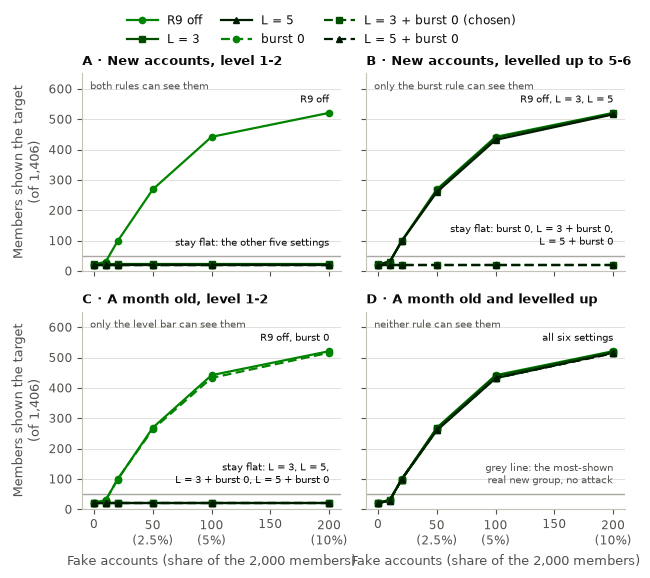

In [12]:
L_COLOUR = br.R9_L_COLOURS                               # one green, darker for a higher level bar; L = 1 is the proposed design's green
L_MARKER = {1: 'o', 3: 's', 5: '^'}                      # a marker per level bar too, so the lines never rely on colour alone
notes = {'fresh': 'both rules can see them',
         'levelled': 'only the burst rule can see them',
         'aged': 'only the level bar can see them',
         'both': 'neither rule can see them'}



def bundle_text(names, per_line=2):
    # Settings whose lines lie on top of each other, named in words, per_line names per line
    if len(names) == len(SETTINGS):
        return 'all six settings'
    if len(names) == len(SETTINGS) - 1:
        return 'the other five settings'
    return ',\n'.join(', '.join(names[i:i + per_line]) for i in range(0, len(names), per_line))


ymax = test_table.target_exposure.max()
top = ymax * 1.25
fig, axes = plt.subplots(2, 2, figsize=(br.WIDTH, 5.4), sharex=True, sharey=True)
for ax, attacker in zip(axes.flat, ATTACKERS):
    d = test_table[test_table.attacker == attacker]
    for L, w in SETTINGS:
        line = d[(d.L == L) & (d.burst_w == w)].sort_values('k')
        ax.plot(line.k, line.target_exposure, color=L_COLOUR[L], marker=L_MARKER[L], markersize=4.5,
                linestyle='-' if w == 1 else (0, (4, 2)), linewidth=1.6, zorder=3 if w == 1 else 4)
    ax.axhline(bar_test, color='#a9a8a2', linewidth=1.0, zorder=1)
    ax.set_title(ATTACKERS[attacker]['label'], fontsize=9)
    ax.text(0.03, 0.96, notes[attacker], transform=ax.transAxes, va='top', ha='left', fontsize=7.5, color=br.MUTED)
    ax.yaxis.grid(True)
    ax.set_xticks([0, 50, 100, 150, 200], ['0', '50\n(2.5%)', '100\n(5%)', '150', '200\n(10%)'])
    # Lines with the same result lie on top of each other, so each bundle is named in words: the settings whose line
    # ends above the grey bar (the attack works), and those that stay under it (the defence holds)
    end = d[d.k == MAX_K].set_index(['L', 'burst_w']).target_exposure
    rise = [(L, w) for L, w in SETTINGS if end[(L, w)] > bar_test]
    flat = [(L, w) for L, w in SETTINGS if end[(L, w)] <= bar_test]
    if rise:
        ax.text(MAX_K, max(end[s] for s in rise) + 0.04 * top, bundle_text([setting_label(*s) for s in rise], per_line=3),
                ha='right', va='bottom', fontsize=7.5, color=br.INK)
    if flat:
        ax.text(MAX_K, bar_test + 0.04 * top, 'stay flat: ' + bundle_text([setting_label(*s) for s in flat]),
                ha='right', va='bottom', fontsize=7.5, color=br.INK)
    else:   # no setting holds here: the space above the bar is free for its label
        ax.text(MAX_K, bar_test + 0.04 * top, 'grey line: the most-shown\nreal new group, no attack',
                ha='right', va='bottom', fontsize=7, color=br.MUTED)
axes[0, 0].set_ylim(0, top)
for ax in axes[1]:
    ax.set_xlabel('Fake accounts (share of the 2,000 members)')
for ax in axes[:, 0]:
    ax.set_ylabel('Members shown the target\n(of 1,406)')
handles = [Line2D([], [], color=L_COLOUR[L], marker=L_MARKER[L], markersize=4.5, linewidth=1.6, linestyle='-' if w == 1 else (0, (4, 2)),
                  label=setting_label(L, w) + (' (chosen)' if (L, w) == (CHOSEN_L, CHOSEN_W) else ''))
           for L, w in SETTINGS]
fig.legend(handles=handles, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.07), handlelength=2.6, columnspacing=1.6)
fig.tight_layout(h_pad=1.2, w_pad=1.0)
br.save_fig(fig, 'e4_sybil.png')
plt.show()

## 7 · How the attack works, and what it takes from real new groups

The attack does not need to beat the popular groups: it only needs to beat the **other new groups**. The fair re-ranking keeps at least one slot in five
for a new or small group (rule R4), the most relevant one, and the target is new. So the fake accounts mostly win that fair-chance slot, which would
otherwise go to an honest new group. Here is attacker A with 100 fake accounts, R9 off:

In [13]:
base_off = test_runs[('fresh', 1, 1.0, 0)]['recs']
hit_off = test_runs[('fresh', 1, 1.0, 100)]['recs']
shown = hit_off[hit_off.group_id == TARGET]
in_bait = set(vis.train.user_id[vis.train.group_id.isin(POPULAR)])
print(f'The target is in {len(shown)} lists (no attack: {int((base_off.group_id == TARGET).sum())}). '
      f'{shown.forced.mean():.0%} of these slots are fair-chance (quota) slots; '
      f'{shown.user_id.isin(in_bait).mean():.0%} of the members shown it are in a bait group.')
row_off = test_table.set_index(['attacker', 'L', 'burst_w', 'k'])
for k in [100, 200]:
    print(f'With {k} fakes: slots for honest new or small groups {row_off.loc[("fresh", 1, 1.0, 0), "honest_newcomer_slots"]} -> '
          f'{row_off.loc[("fresh", 1, 1.0, k), "honest_newcomer_slots"]}; NDCG@5 {row_off.loc[("fresh", 1, 1.0, 0), "ndcg@5"]:.3f} -> '
          f'{row_off.loc[("fresh", 1, 1.0, k), "ndcg@5"]:.3f}')
print('\nThe reasons the members are shown, for the target:')
reason_table = shown.groupby(['reason_code', 'reason_text']).size().sort_values(ascending=False).rename('slots')
reason_table.head(6).to_frame()

The target is in 442 lists (no attack: 21). 86% of these slots are fair-chance (quota) slots; 97% of the members shown it are in a bait group.
With 100 fakes: slots for honest new or small groups 1404 -> 981; NDCG@5 0.528 -> 0.525
With 200 fakes: slots for honest new or small groups 1404 -> 905; NDCG@5 0.528 -> 0.525

The reasons the members are shown, for the target:


slots
reason_code    reason_text                                              
new_group      A new group: we show new groups so they get a f...    380
shared_members 70 members of Finals countdown are in it               37
               69 members of Weightlifting for beginners are i...     16
               64 members of Korean conversation club are in it        7
similar_group  Similar to Calculus study group, which you joined       2

**The attack steals the fair-chance slot.** With 100 fake accounts and R9 off, the target is in 442 lists. In 86% of them it holds the slot the
re-ranking keeps for new or small groups (rule R4), and 97% of the members shown it are in one of the bait groups. The target doesn't need to beat
the popular groups: its average rank only goes from 86 to 62 (of about 125). It only needs to be the *most relevant new group* for these
members, and the fake accounts' links to the bait groups make it that.

- **Honest new groups pay for it.** Their slots drop from 1,404 to 981 with 100 fakes, and to 905 with 200.
- **Accuracy hardly moves** (NDCG@5 0.528 to 0.525), because the slot the target takes rarely held a correct guess anyway. Someone watching
  accuracy alone would never see this attack.
- **A fairness rule gives the attack its foothold:** R4 holds a slot open, and the fake accounts aim at it. R9 keeps that slot for the groups
  it was made for.
- **The reasons shown:** 380 of the target's 442 slots say "A new group: we show new groups...". The other 60 say "*N* members of [a bait group]
  are in it", and most of those *N* members are the fake accounts. The sentence is true by the numbers but misleading: a reason is only as honest
  as the counts behind it (plan: transparency against manipulation, E4 with E6).

## 8 · What R9 costs honest newcomers when there is no attack

R9 turns down honest members too, and they are mostly new members. Two things could suffer:

- **new members' own suggestions.** No tested member is a new account: new members have only 1 or 2 groups, and the test hid groups only from
  members with 3 or more. So we build a small **new-member quiz**: for each young account with exactly 2 groups, we hide the one it joined last
  (posts and likes that would give it away are removed too), and see whether the recommender finds it.
- **new groups' exposure.** If new members' joins count less, the groups they join could be shown less. We measure the slots that go to groups created
  in the last 30 days, for the 1,406 tested members.

No setting is chosen here: these are the costs of the six settings of the figure, measured once.

In [14]:
young_ids = real.index[young]
off_limits = set(vis.groups.group_id[vis.groups.hidden_by_mods == 1])
young_mem = vis.train[vis.train.user_id.isin(young_ids)]
two = young_mem.groupby('user_id').filter(lambda r: len(r) == 2 and not r.group_id.isin(off_limits).any())
rng = np.random.default_rng(SEED)
two = two.assign(tie=rng.random(len(two))).sort_values(['user_id', 'joined_day', 'tie'])   # a seeded coin breaks equal days
nm_hidden = two.groupby('user_id').tail(1)[['user_id', 'group_id', 'joined_day']]
nm_posts, nm_likes = br.drop_leaks(vis.posts, vis.likes, nm_hidden)
nm_vis = replace(vis, train=vis.train.drop(index=nm_hidden.index).reset_index(drop=True), posts=nm_posts, likes=nm_likes)
nm_users = sorted(nm_hidden.user_id)
print(f'New-member quiz: {len(nm_users)} young accounts with 2 groups; one each hidden '
      f'({nm_hidden.group_id.isin(discover).sum()} of the hidden groups are on Discover and can be found at all).')

cost_rows, nm_per_user = {}, {}
for L, w in SETTINGS:
    c = replace(cfg, L=L, burst_w=w)
    recs = test_runs[('fresh', L, w, 0)]['recs']
    shown_new = recs.group_id.isin(NEW_GROUPS)
    nm_lists = br.lists_from(br.recommend(nm_users, nm_vis, c, clusters=CLUSTERS))
    nm_per_user[(L, w)] = br.relevance_per_user(nm_lists, nm_hidden)
    cost_rows[setting_label(L, w)] = {
        'honest memberships turned down': weight_turned_down(vis, L, w),
        'NDCG@5 (tested members)': br.relevance_per_user(br.lists_from(recs), ans.test)['ndcg@5'].mean(),
        'slots for new groups': shown_new.mean(), 'new groups shown (of %d)' % len(NEW_GROUPS): recs.group_id[shown_new].nunique(),
        'newcomer share': row_off.loc[('fresh', L, w, 0), 'newcomer_share'],
        'NDCG@5 (new-member quiz)': nm_per_user[(L, w)]['ndcg@5'].mean(),
        'hit rate (new-member quiz)': nm_per_user[(L, w)]['hit_rate'].mean()}
cost = pd.DataFrame(cost_rows).T.reindex(order)
off_t = br.relevance_per_user(br.lists_from(test_runs[('fresh', 1, 1.0, 0)]['recs']), ans.test)['ndcg@5']
ch_t = br.relevance_per_user(br.lists_from(test_runs[('fresh', CHOSEN_L, CHOSEN_W, 0)]['recs']), ans.test)['ndcg@5']
test_cost_low, test_cost_high = br.bootstrap_ci(off_t - ch_t)
nm_diff = nm_per_user[(1, 1.0)]['ndcg@5'] - nm_per_user[(CHOSEN_L, CHOSEN_W)]['ndcg@5']
nm_cost_low, nm_cost_high = br.bootstrap_ci(nm_diff)
nm_off_low, nm_off_high = br.bootstrap_ci(nm_per_user[(1, 1.0)]['ndcg@5'])
br.save_table(cost, 'e4_newcomer_cost.csv', decimals=4)
print(f'Chosen vs R9 off, NDCG@5 lost by tested members: {(off_t - ch_t).mean():+.4f} (95% range {test_cost_low:+.4f} to {test_cost_high:+.4f}); '
      f'by new members: {nm_diff.mean():+.4f} (95% range {nm_cost_low:+.4f} to {nm_cost_high:+.4f}; '
      f'R9 off itself: {nm_off_low:.3f} to {nm_off_high:.3f}, from only {len(nm_users)} members).')
cost.round(3)

New-member quiz: 80 young accounts with 2 groups; one each hidden (80 of the hidden groups are on Discover and can be found at all).


Chosen vs R9 off, NDCG@5 lost by tested members: +0.0014 (95% range -0.0029 to +0.0055); by new members: -0.0109 (95% range -0.0309 to +0.0076; R9 off itself: 0.250 to 0.413, from only 80 members).


,honest memberships turned down,NDCG@5 (tested members),slots for new groups,new groups shown (of 23),newcomer share,NDCG@5 (new-member quiz),hit rate (new-member quiz)
R9 off,0.0,0.528,0.042,20.0,0.203,0.331,0.488
L = 3,74.0,0.526,0.042,20.0,0.203,0.332,0.488
L = 5,200.0,0.525,0.042,20.0,0.194,0.330,0.475
burst 0,282.0,0.529,0.041,20.0,0.194,0.342,0.500
L = 3 + burst 0,282.0,0.527,0.041,20.0,0.195,0.342,0.500
L = 5 + burst 0,296.0,0.527,0.040,20.0,0.194,0.326,0.488


**A younger network.** In this community only 15% of the accounts are young. BOING is new (assumption 1 of the report): in its first months most
members will be young. What does the burst weight cost then? We pretend that every account made in the last 183 days is young (about half of them)
and measure accuracy with no attack, at the chosen level bar.

In [15]:
YOUNG_STRESS = 183
young_rows = {}
young_recs = Parallel(n_jobs=N_JOBS, max_nbytes=None)(
    delayed(br.recommend)(tested, vis, replace(cfg, L=CHOSEN_L, burst_w=w, young_days=YOUNG_STRESS), clusters=CLUSTERS) for w in WEIGHTS)
for w, recs in zip(WEIGHTS, young_recs):
    per_user = br.relevance_per_user(br.lists_from(recs), ans.test)
    young_rows[f'burst {w:g}' if w < 1 else 'no burst rule'] = {
        'young accounts': int((real.created_day > br.TODAY - YOUNG_STRESS).sum()),
        'honest memberships turned down': weight_turned_down(vis, CHOSEN_L, w, YOUNG_STRESS),
        'NDCG@5': per_user['ndcg@5'].mean(), 'hit rate': per_user['hit_rate'].mean(),
        'cost vs no burst rule': np.nan}
young_net = pd.DataFrame(young_rows).T
young_net['cost vs no burst rule'] = young_net.loc['no burst rule', 'NDCG@5'] - young_net['NDCG@5']
young_net['young accounts'] = young_net['young accounts'].astype(int)
br.save_table(young_net, 'e4_young_network.csv', decimals=4)
young_net.round(3)

,young accounts,honest memberships turned down,NDCG@5,hit rate,cost vs no burst rule
no burst rule,1025,74.00,0.526,0.654,0.000
burst 0.5,1025,1446.50,0.530,0.659,-0.004
burst 0.25,1025,2132.75,0.529,0.657,-0.003
burst 0.1,1025,2544.50,0.531,0.661,-0.005
burst 0,1025,2819.00,0.530,0.661,-0.005


**What R9 costs when there is no attack: nothing we can measure.**

- **Tested members:** NDCG@5 is 0.528 with R9 off and 0.527 with the chosen setting. The paired difference is 0.0014 (95% range −0.0029 to +0.0055),
  so it could be zero.
- **New members** (the new-member quiz, 80 young accounts with 2 groups): 0.331 with R9 off, 0.342 with the chosen setting. Their own suggestions
  don't suffer, because R9 decides whose joins shape *other* people's suggestions, not who gets suggestions. With only 80 members, the 95% range
  of the difference is wide (−0.031 to +0.008).
- **New groups** get 4.2% of the slots with R9 off and 4.1% with the chosen setting; 20 of the 23 new groups are shown in both.
- **One side effect:** the newcomer share falls from 20.3% to 19.5%. Group sizes now count only the members who count. So one group with 11 members,
  2 of them young, looks like it has 9: it then counts as *small* and shares the fair-chance slot with the truly new or small groups. We keep this,
  because a group made mostly of new members is a fair candidate for that slot, and the effect is small.
- **282 of the 6,367 honest memberships (4.4%) are turned down**, all of them by accounts made in the last 30 days. Each one starts counting on
  the account's 30th day.

**In a younger network**, where every account made in the last 183 days counts as young (1,025 accounts holding 44% of the memberships), turning
their joins down doesn't cost accuracy either: NDCG@5 is 0.526 without the burst rule and 0.530 with weight 0. Here, the older half of the members
is enough to learn from. This has a limit: at launch, when nearly every account is young, weight 0 would leave almost nothing to learn from. BOING
should switch the burst rule on once enough accounts are more than 30 days old, and use the level bar alone until then.

## 9 · Does it depend on which group is attacked?

We repeat the attack on every new, open group on Discover with at most 2 members (the target is one of them), with 100 fake accounts of kind B
(levelled up: the level bar cannot see them; with R9 off, kinds A and B are the same). How many more members are shown each group, R9 off and with the chosen setting?

In [16]:
targets = [g for g in discover if created[g] > br.TODAY - br.NEW_DAYS and size[g] <= 2]
pairs = [((L, w), g) for L, w in [(1, 1.0), (CHOSEN_L, CHOSEN_W)] for g in targets]
rob_runs = run_attacks(vis, tested, [('levelled', RULE_K, replace(cfg, L=L, burst_w=w), g) for (L, w), g in pairs], with_ranks=False)
rob_rows = []
for ((L, w), g), run in zip(pairs, rob_runs):
    before = int((test_runs[('fresh', L, w, 0)]['recs'].group_id == g).sum())     # the same setting, no attack
    after = int((run['recs'].group_id == g).sum())
    rob_rows.append({'group_id': g, 'group': name[g], 'members': int(size[g]), 'days old': int(br.TODAY - created[g]),
                     'setting': setting_label(L, w), 'no attack': before, 'attacked': after, 'gain': after - before})
rob = pd.DataFrame(rob_rows)
rob_wide = rob.pivot_table(index=['group_id', 'group', 'members', 'days old'], columns='setting', values=['no attack', 'attacked', 'gain'])
rob_wide.columns = [f'{s}: {m}' for m, s in rob_wide.columns]
br.save_table(rob.set_index(['group_id', 'setting']), 'e4_targets.csv')
gain = rob.pivot_table(index='group_id', columns='setting', values='gain')
print(f'{len(targets)} groups attacked with {RULE_K} fake accounts each. Median gain: R9 off {gain["R9 off"].median():.0f} members, '
      f'chosen {gain[setting_label(CHOSEN_L, CHOSEN_W)].median():.0f}. Largest gain: R9 off {gain["R9 off"].max():.0f}, '
      f'chosen {gain[setting_label(CHOSEN_L, CHOSEN_W)].max():.0f}.')
rob_wide

42 runs, 42 recommend() calls
21 groups attacked with 100 fake accounts each. Median gain: R9 off 414 members, chosen 0. Largest gain: R9 off 464, chosen 0.


,,,,L = 3 + burst 0: attacked,R9 off: attacked,L = 3 + burst 0: gain,R9 off: gain,L = 3 + burst 0: no attack,R9 off: no attack
group_id,group,members,days old,,,,,,
123,IELTS prep squad,1,27,18.0,319.0,0.0,301.0,18.0,18.0
124,Daily Digital painting,1,24,10.0,416.0,0.0,406.0,10.0,10.0
126,Morning Calisthenics,1,23,2.0,409.0,0.0,407.0,2.0,2.0
127,Arabic for beginners,1,21,5.0,446.0,0.0,442.0,5.0,4.0
130,Daily Sketching,2,19,3.0,332.0,0.0,329.0,3.0,3.0
131,JavaScript from zero,1,19,26.0,416.0,0.0,390.0,26.0,26.0
132,Learn Music theory together,1,18,3.0,436.0,0.0,433.0,3.0,3.0
136,Getting good at Freelancing,1,13,23.0,441.0,0.0,417.0,23.0,24.0
137,Reading club,0,13,2.0,451.0,0.0,448.0,2.0,3.0


**Every small new group is just as easy to push, and R9 protects all of them.** We attacked each of the 21 new, open groups on Discover with at most
2 members, using 100 levelled-up fake accounts (kind B). With R9 off, each one gained between 301 and 464 lists (median 414), so the target we picked
is typical, not an easy case. With the chosen setting, none of them gained a single list.

## 10 · Fake accounts that also post and like (the default list)

So far the fake accounts only **joined** groups. But the list every member sees by default (personalisation off, rule R1) ranks groups by their
**recent activity** (posts in the last 30 days and the likes on them) and their newness, and R9 as built above only filters joins: a young,
levelled-up account's posts still count. So here each fake account also **posts once** in the target (in the last 2 days) and **likes up to 5**
other fakes' posts there.

- **The target:** an older group that no tested member's default list shows, picked by a fixed rule: the open Discover group with the smallest id,
  created more than 30 days ago, that is in no default list with no attack. (A new group already gets a boost for being new.)
- **Three settings:** R9 off; L = 3 and burst_w = 0 acting on **joins only** (`r9_scope = 'joins'`, what sections 4 to 9 chose); and the same
  acting on **joins, posts, likes and friends** (`r9_scope = 'all'`): a young or low-level account's posts and likes then count for nothing either.
- **Measured** on the tested members: how many default lists, and how many personalised lists, show the target, and whether the statistics change.

In [17]:
def add_posting_fakes(v, k, attacker, target):
    # The fakes of add_fake_accounts (joins: the target and 1 to 3 bait groups), and each one also posts once in the target in the last 2 days
    # (never before it was made) and likes up to 5 other fakes' posts there. Returns (copy, fake ids).
    attacked, ids = add_fake_accounts(v, k, attacker, target=target)
    if k == 0:
        return attacked, ids
    rng = np.random.default_rng(SEED + 1)
    made = attacked.users.set_index('user_id').created_day.reindex(ids).to_numpy()
    p0 = int(v.posts.post_id.max()) + 1
    posts = pd.DataFrame({'post_id': np.arange(p0, p0 + len(ids)), 'user_id': ids, 'group_id': target,
                          'day': np.maximum(made, rng.integers(br.TODAY - BURST_DAYS + 1, br.TODAY + 1, len(ids))),
                          'text': 'Come and join us!', 'likes': 0, 'hidden_by_mods': 0})
    likes = []
    for i, u in enumerate(ids):
        others = np.delete(posts.post_id.to_numpy(), i)
        likes += [(int(p), int(u)) for p in rng.choice(others, size=min(5, len(others)), replace=False)] if len(others) else []
    likes = pd.DataFrame(likes, columns=['post_id', 'user_id'])
    posts['likes'] = posts.post_id.map(likes.groupby('post_id').size()).fillna(0).astype(int)
    return replace(attacked, posts=pd.concat([v.posts, posts[list(v.posts.columns)]], ignore_index=True),
                   likes=pd.concat([v.likes, likes[list(v.likes.columns)]], ignore_index=True)), ids


R9_SCOPES = {'R9 off': replace(cfg, L=1, burst_w=1.0),
             'L = 3 + burst 0, joins only': replace(cfg, L=3, burst_w=0.0, r9_scope='joins'),
             'L = 3 + burst 0, joins, posts, likes and friends': replace(cfg, L=3, burst_w=0.0, r9_scope='all')}
off_lists0 = br.recommend(tested, vis, replace(cfg, personal=False), clusters=CLUSTERS)
OLD_TARGET = int(min(g for g in discover if created[g] <= br.TODAY - br.NEW_DAYS and g not in set(off_lists0.group_id)))
act_rows = []
for setting, c in R9_SCOPES.items():
    clean_stats = br.stats_for(vis, c)
    base_off_ = br.recommend(tested, vis, replace(c, personal=False), clean_stats, clusters=CLUSTERS)
    base_on_ = br.recommend(tested, vis, c, clean_stats, clusters=CLUSTERS)
    for attacker in ATTACKERS:
        for k in [0, 20, 100]:
            if k == 0 and attacker != 'fresh':
                continue
            v_, ids_ = add_posting_fakes(vis, k, attacker, OLD_TARGET)
            st = br.stats_for(v_, c)
            unchanged = same_stats(st, clean_stats) and st.posts_week.equals(clean_stats.posts_week)
            r_off = base_off_ if (unchanged and k > 0) else br.recommend(tested, v_, replace(c, personal=False), st, clusters=CLUSTERS)
            r_on = base_on_ if (unchanged and k > 0) else br.recommend(tested, v_, c, st, clusters=CLUSTERS)
            act_rows.append({'setting': setting, 'attacker': ATTACKERS[attacker]['label'] if k else 'no attack', 'k': k,
                             'statistics unchanged': unchanged,
                             'target activity (posts + likes counted)': float(st.activity[OLD_TARGET]),
                             'default lists showing the target': int((r_off.group_id == OLD_TARGET).sum()),
                             'personalised lists showing the target': int((r_on.group_id == OLD_TARGET).sum())})
act_attack = pd.DataFrame(act_rows).set_index(['setting', 'attacker', 'k'])
br.save_table(act_attack, 'e4_activity_attack.csv')
print(f'Target: {name[OLD_TARGET]} (group {OLD_TARGET}, {int(size[OLD_TARGET])} members, {int(br.TODAY - created[OLD_TARGET])} days old); '
      f'cap: {max(1, int(np.floor(cfg.c * K * len(tested) + 1e-9)))} lists.')
act_attack

Target: 3D modelling club (group 1, 149 members, 365 days old); cap: 703 lists.


statistics unchanged  \
setting                                          attacker                             k                           
R9 off                                           no attack                            0                    True   
                                                 A · New accounts, level 1-2          20                  False   
                                                                                      100                 False   
                                                 B · New accounts, levelled up to 5-6 20                  False   
                                                                                      100                 False   
                                                 C · A month old, level 1-2           20                  False   
                                                                                      100                 False   
                                                 D · A month old and levelled up      20                  False   
                                                                                      100                 False   
L = 3 + burst 0, joins only                      no attack                            0                    True   
                                                 A · New accounts, level 1-2          20                   True   
                                                                                      100                  True   
                                                 B · New accounts, levelled up to 5-6 20                  False   
                                                                                      100                 False   
                                                 C · A month old, level 1-2           20                   True   
                                                                                      100                  True   
                                                 D · A month old and levelled up      20                  False   
                                                                                      100                 False   
L = 3 + burst 0, joins, posts, likes and friends no attack                            0                    True   
                                                 A · New accounts, level 1-2          20                   True   
                                                                                      100                  True   
                                                 B · New accounts, levelled up to 5-6 20                   True   
                                                                                      100                  True   
                                                 C · A month old, level 1-2           20                   True   
                                                                                      100                  True   
                                                 D · A month old and levelled up      20                  False   
                                                                                      100                 False   

                                                                                           target activity (posts + likes counted)  \
setting                                          attacker                             k                                              
R9 off                                           no attack                            0                                       32.0   
                                                 A · New accounts, level 1-2          20                                     152.0   
                                                                                      100                                    632.0   
                                                 B · New accounts, levelled up to 5-6

**R9 must act on posts and likes too, not only on joins.** The target, *3D modelling club* (149 members, a year old), is in no default
list with no attack. With R9 off, 20 fake accounts that join, post once and like a few posts put it into **703** default lists, the most the
global cap allows (10% of the slots here). With R9 on joins only, the young levelled-up accounts (B) are kept out of every membership statistic,
yet their posts and likes still put the target into **703** default lists: the activity count is a statistic about other members too, and it was
not filtered. With R9 acting on joins, posts, likes and friends (`r9_scope = 'all'`), attackers A, B and C change **no statistic at all**
(memberships and activity), so the target gains nothing, in the default list (0) or the personalised one. Attacker D (a month old and levelled up)
is R9's known limit here too: it reaches the cap. Because the default list is the same for everyone, an attack on it reaches the cap with only
20 accounts, where the personalised lists barely move (68 to 101 lists with 100 fakes). The cost of the wider R9 to honest members is
measured with the final design in notebook 11.

## 11 · Recommendation

The chosen setting, why, and the numbers behind it, saved to `results/e4_recommendation.json` for the report.

In [18]:
def at(attacker, L, w, k, col='target_exposure'):
    return row_off.loc[(attacker, L, w, k), col]

ch = (CHOSEN_L, CHOSEN_W)
act_at = lambda setting, attacker, k, col: act_attack.loc[(setting, ATTACKERS[attacker]['label'] if k else 'no attack', k), col]
rec = {
    'L': int(CHOSEN_L), 'burst_w': float(CHOSEN_W), 'young_days': int(cfg.young_days), 'r9_scope': 'all',
    'r9_scope_why': ('with R9 on joins only, young levelled-up fake accounts that post and like push a group into the default list '
                     '(section 10); with R9 on joins, posts, likes and friends they change no statistic'),
    'activity_attack': {
        'target_group': {'group_id': OLD_TARGET, 'name': name[OLD_TARGET], 'members': int(size[OLD_TARGET]),
                         'days_old': int(br.TODAY - created[OLD_TARGET])},
        'default_lists_showing_target': {s: {a: {int(k): int(act_at(s, a, k, 'default lists showing the target')) for k in [20, 100]}
                                             for a in ATTACKERS} for s in R9_SCOPES},
        'personalised_lists_showing_target': {s: {a: {int(k): int(act_at(s, a, k, 'personalised lists showing the target')) for k in [20, 100]}
                                                  for a in ATTACKERS} for s in R9_SCOPES},
        'statistics_unchanged': {s: {a: {int(k): bool(act_at(s, a, k, 'statistics unchanged')) for k in [20, 100]} for a in ATTACKERS}
                                 for s in R9_SCOPES},
        'no_attack_default_lists': {s: int(act_at(s, 'fresh', 0, 'default lists showing the target')) for s in R9_SCOPES}},
    'chosen_on': 'practice quiz (validation split of the training data); reported on the test',
    'rule': ('lowest L, then largest burst_w, such that with up to %d fake accounts (attackers A, B, C) the target is shown to no more '
             'members than the most-shown honest new group with no attack; check: NDCG@5 cost within the 95%% range' % RULE_K),
    'target_group': {'group_id': int(TARGET), 'name': name[TARGET], 'members': int(size[TARGET]), 'days_old': int(br.TODAY - created[TARGET])},
    'bait_groups': [{'group_id': int(g), 'name': name[g], 'members': int(size[g])} for g in POPULAR],
    'practice_quiz': {'settings_passing': [setting_label(L, w) for L, w in passing.index],
                      'members_quizzed': len(val_users),
                      'worst_target_exposure_up_to_%d_fakes' % RULE_K: {
                          setting_label(L, w): {'A': int(r['worst with fresh']), 'B': int(r['worst with levelled']),
                                                'C': int(r['worst with aged']), 'bar': int(r['bar: top honest new group'])}
                          for (L, w), r in choice.iterrows()},
                      'ndcg@5_r9_off': round(float(off_val.mean()), 4), 'ndcg@5_chosen': round(float(chosen_val.mean()), 4),
                      'ndcg@5_cost': round(float(val_cost.mean()), 4), 'ndcg@5_cost_95': [round(val_cost_low, 4), round(val_cost_high, 4)]},
    'test': {
        'members_tested': len(tested),
        'bar_top_honest_new_group': bar_test,
        'target_exposure': {a: {setting_label(L, w): {int(k): int(at(a, L, w, k)) for k in KS} for L, w in [(1, 1.0), ch]} for a in ATTACKERS},
        'places_per_fake_A': {setting_label(L, w): {int(k): round(float(at('fresh', L, w, k, 'places_per_fake')), 3) for k in KS[1:]}
                              for L, w in [(1, 1.0), ch]},
        'target_avg_rank_A': {setting_label(L, w): {int(k): round(float(at('fresh', L, w, k, 'target_avg_rank')), 1) for k in KS}
                              for L, w in [(1, 1.0), ch]},
        'ndcg@5_A': {setting_label(L, w): {int(k): round(float(at('fresh', L, w, k, 'ndcg@5')), 4) for k in KS} for L, w in [(1, 1.0), ch]},
        'honest_newcomer_slots_A': {setting_label(L, w): {int(k): int(at('fresh', L, w, k, 'honest_newcomer_slots')) for k in KS}
                                    for L, w in [(1, 1.0), ch]},
    },
    'cost_no_attack': {
        'ndcg@5_tested_r9_off': round(float(off_t.mean()), 4), 'ndcg@5_tested_chosen': round(float(ch_t.mean()), 4),
        'ndcg@5_tested_cost_95': [round(test_cost_low, 4), round(test_cost_high, 4)],
        'new_member_quiz_users': len(nm_users),
        'ndcg@5_new_members_r9_off': round(float(nm_per_user[(1, 1.0)]['ndcg@5'].mean()), 4),
        'ndcg@5_new_members_chosen': round(float(nm_per_user[ch]['ndcg@5'].mean()), 4),
        'ndcg@5_new_members_cost_95': [round(nm_cost_low, 4), round(nm_cost_high, 4)],
        'slots_for_new_groups_r9_off': round(float(cost.loc['R9 off', 'slots for new groups']), 4),
        'slots_for_new_groups_chosen': round(float(cost.loc[setting_label(*ch), 'slots for new groups']), 4),
        'honest_memberships_turned_down': round(weight_turned_down(vis, *ch), 1),
        'honest_memberships': len(mem)},
    'burst_weights_attacker_B_test': {f'burst_w = {w:g}': {int(k): int(e) for k, e in d.set_index('k').target_exposure.items()}
                                      for w, d in bw.groupby('burst_w', sort=False)},
    'young_network_183_days': {k_: round(float(v_), 4) for k_, v_ in young_net['NDCG@5'].items()},
    'targets_robustness_median_gain': {s: float(gain[s].median()) for s in gain.columns},
    'residual_risk_D_k100_k200': {setting_label(L, w): [int(at('both', L, w, 100)), int(at('both', L, w, 200))] for L, w in [(1, 1.0), ch]},
    'limits': ['R9 reads only level and account age: fake accounts that wait 30 days and reach level %d (attacker D) are not stopped, '
               'whether they join, post or like' % CHOSEN_L,
               'R9 must act on posts, likes and friends as well as joins (r9_scope = all): on joins only, young levelled-up fakes that '
               'post push a group into the default list',
               'at launch, when nearly every account is young, burst_w = 0 leaves almost nothing to learn from: switch the burst rule on '
               'once enough accounts are older than %d days, and use the level bar alone until then' % cfg.young_days,
               'group sizes count only the members who count, so a group of mostly young members can look small and share the '
               'newcomer slot (newcomer share %.3f with R9 off, %.3f chosen)' % (cost.loc['R9 off', 'newcomer share'],
                                                                                cost.loc[setting_label(*ch), 'newcomer share'])],
}
(br.RESULTS / 'e4_recommendation.json').write_text(json.dumps(rec, indent=2))
print(json.dumps({k: rec[k] for k in ['L', 'burst_w', 'young_days', 'target_group']}, indent=2))

{
  "L": 3,
  "burst_w": 0.0,
  "young_days": 30,
  "target_group": {
    "group_id": 149,
    "name": "Calculus problem of the day",
    "members": 1,
    "days_old": 4
  }
}


**Recommendation: L = 3 and burst_w = 0, where young means made in the last 30 days, acting on joins, posts, likes and friends.** In plain
words: *a member's joins, posts and likes start shaping other people's suggestions once the account is 30 days old and at level 3.* Until then, the
member gets suggestions like everyone else.

- **It works.** Against the plan's attack (A) and the two cheaper ways around one rule (B, C), the target stays at 20 lists for up to 200 fake
  accounts (10% of the members). With R9 off, 100 fake accounts give it 442. Every small new group we tried behaves the same way.
- **It must cover posts and likes, not only joins** (section 10). Fakes that also post and like push an older group into the default list that
  every member sees, unless R9 filters their posts and likes too (`r9_scope = 'all'`).
- **The burst weight must be 0, not 0.25.** A weight between 0 and 1 only multiplies the number of fake accounts needed, and an account costs a
  wallet and a username. At 0.25, 100 levelled-up fakes still put the target in 131 lists (the bar is 49). Weight 0 turns the rule into a
  waiting period, which no number of accounts can shorten.
- **L = 3, not 5.** Both work, but L = 3 turns down fewer honest members. Level 3 is 125 XP: an evening of play for a real member.
- **It costs honest members nothing we can measure** (section 8): not tested members, not new members, not new groups.
- **Its limit:** fake accounts that wait a month *and* reach level 3 (D) get through, with 433 lists from 100 of them. R9 makes the attack slow
  and costly (100 accounts, each 30 days old with 125 XP of play), not impossible. Beyond R9, the cap c (no group gets more than 10% of all slots),
  reports and moderation in HQ remain. The plan's other idea, robust aggregates (median-of-means or trimmed counts), is left for later: with the
  fake accounts left out completely, there is nothing left for it to trim.
- **At launch,** when nearly every account is young, the burst rule would leave almost nothing to learn from. Switch it on once enough accounts
  are more than 30 days old, and use the level bar alone until then.

## 12 · Checks

In [19]:
e1 = pd.read_csv(br.RESULTS / 'e1_methods.csv', index_col=0)
off0 = br.evaluate(br.lists_from(base_off), ans.test, vis, ans.group_topic)
cols = ['hit_rate', 'precision@5', 'recall@5', 'ndcg@5', 'newcomer_share', 'gini', 'coverage', 'largest_share', 'topics_per_list']

# The shortcuts are exact. (1) 200 fakes kept out by L = 3, run plainly here: the sweep used the no-attack call instead.
c3 = replace(cfg, L=3)
kept_out, _ = add_fake_accounts(vis, MAX_K, 'fresh')
full = br.recommend(tested, kept_out, c3, br.stats_for(kept_out, c3), clusters=CLUSTERS)
# (2) Attacker B, R9 off, 50 fakes, run plainly here: in the sweep it shared attacker A's call, made in another process.
b50, _ = add_fake_accounts(vis, 50, 'levelled')
plain_b50 = br.recommend(tested, b50, cfg, br.stats_for(b50, cfg), clusters=CLUSTERS)
# Each account counts once: a fake that joins the target twice changes nothing
att, ids_ = add_fake_accounts(vis, 50, 'levelled')
twice = replace(att, train=pd.concat([att.train, att.train[att.train.user_id == ids_[0]]], ignore_index=True))
# The burst weight: a young member adds exactly burst_w to each of its groups' sizes
s25 = br.stats_for(vis, replace(cfg, burst_w=0.25))
counted = vis.train[vis.train.user_id.isin(br.stats_for(vis).counted)]
is_young = users.created_day.reindex(counted.user_id).to_numpy() > br.TODAY - cfg.young_days
expected = (counted[~is_young].groupby('group_id').size().reindex(gids, fill_value=0)
            + 0.25 * counted[is_young].groupby('group_id').size().reindex(gids, fill_value=0))
fa, fa_ids = add_fake_accounts(vis, MAX_K, 'fresh')
fa_users = fa.users.set_index('user_id').loc[fa_ids]
fa_joins = fa.train[fa.train.user_id.isin(fa_ids)]
fa_groups = fa_joins.groupby('user_id').group_id.agg(set)
joins_of = {a: add_fake_accounts(vis, 20, a)[0].train.iloc[len(vis.train):][['user_id', 'group_id']].reset_index(drop=True)
            for a in ATTACKERS}
cap = max(1, int(np.floor(cfg.c * K * len(tested) + 1e-9)))

checks = {
    'the defaults are unchanged (L = 1, burst_w = 1): R9 is off unless a notebook turns it on':
        cfg.L == 1 and cfg.burst_w == 1 and same_stats(br.stats_for(vis), br.stats_for(vis, replace(cfg, burst_w=1.0))),
    'with no attack and R9 off, the results equal notebook 06\'s proposed design (E1 table)':
        np.allclose(off0[cols].astype(float).round(3), e1.loc[br.label('reranked'), cols].astype(float).round(3)),
    'the recommender never gets is_fake: an attacked copy has exactly the visible columns':
        list(fa.users.columns) == list(vis.users.columns) and 'is_fake' not in fa.users.columns and 'interests' not in fa.users.columns,
    'the data files are not changed: sim_v1 still has no fake account and the same memberships':
        int(br.load_answers().user_is_fake.sum()) == 0 and len(br.load_visible().train) == len(vis.train),
    'fake accounts are as planned: made in the last 7 days, level 1-2, no friends, posts, likes or topics':
        fa_users.created_day.between(br.TODAY - FAKE_DAYS + 1, br.TODAY).all() and fa_users.level.isin([1, 2]).all()
        and not (set(vis.friendships.user_a) | set(vis.friendships.user_b)) & set(fa_ids)
        and not set(fa.posts.user_id) & set(fa_ids) and not set(fa.topics.user_id) & set(fa_ids),
    'each fake joins the target and 1 to 3 bait groups, in the last 2 days, never before it was made':
        all(TARGET in s and 2 <= len(s) <= 4 and s <= {TARGET, *POPULAR} for s in fa_groups)
        and len(fa_groups) == MAX_K and len(fa_joins) == fa_groups.map(len).sum()
        and fa_joins.joined_day.ge(br.TODAY - BURST_DAYS + 1).all()
        and (fa_joins.joined_day.to_numpy() >= fa.users.set_index('user_id').created_day.reindex(fa_joins.user_id).to_numpy()).all(),
    'k fake accounts are the first k of the same 200, for every attacker (only level and age differ)':
        all(joins_of[a].equals(joins_of['fresh']) for a in ATTACKERS)
        and np.array_equal(add_fake_accounts(vis, 10)[1], add_fake_accounts(vis, 20)[1][:10]),
    'the figure\'s colours: R9 off (L = 1) is drawn in the proposed design\'s green, as in every other figure':
        br.R9_L_COLOURS[1] == br.colour('reranked'),
    'no fake account ever gets a list': all(not set(r['recs'].user_id) - set(tested) for r in test_runs.values()),
    'shared runs are exact: 200 fakes kept out by L = 3, run plainly, give exactly the no-attack rows':
        full.equals(test_runs[('fresh', 3, 1.0, 0)]['recs']),
    'shared and parallel runs are exact (same seed, same results): attacker B, R9 off, 50 fakes, run plainly here, gives the sweep\'s rows':
        test_runs[('levelled', 1, 1.0, 50)]['key'] == test_runs[('fresh', 1, 1.0, 50)]['key']
        and plain_b50.equals(test_runs[('levelled', 1, 1.0, 50)]['recs']),
    'each account counts once: a fake joining the target twice changes no statistic':
        same_stats(br.stats_for(twice, cfg), br.stats_for(att, cfg)),
    'the burst rule: with burst_w = 0.25, each group size = older members + 0.25 x young members':
        np.allclose(s25.sizes.to_numpy(), expected.to_numpy()),
    'with the level bar above the fakes\' level, or burst_w = 0 against new fakes, they carry no weight':
        (test_table[(test_table.k > 0) & (((test_table.L >= 3) & test_table.attacker.isin(['fresh', 'aged']))
                                         | ((test_table.burst_w == 0) & test_table.attacker.isin(['fresh', 'levelled'])))].fake_weight == 0).all(),
    'the global cap (R4) holds in every run: the target never takes more than c of the slots':
        test_table.target_exposure.max() <= cap,
    'no rule of the re-ranker had to be relaxed in any test run': (test_table.times_relaxed == 0).all(),
    'posting fakes: with R9 on joins only, B (young, levelled up) still pushes the target into the default lists; with R9 on posts and likes too, '
    'A, B and C change no statistic and the target gains nothing':
        act_at('L = 3 + burst 0, joins only', 'levelled', 20, 'default lists showing the target') > 0
        and all(act_at('L = 3 + burst 0, joins, posts, likes and friends', a, k, 'statistics unchanged')
                and act_at('L = 3 + burst 0, joins, posts, likes and friends', a, k, 'default lists showing the target') == 0
                for a in PROTECT for k in [20, 100]),
    "posting fakes: the numbers written in section 10 are this run's (703 lists, target group 1)":
        OLD_TARGET == 1 and act_at('R9 off', 'fresh', 20, 'default lists showing the target') == 703
        and act_at('L = 3 + burst 0, joins only', 'levelled', 20, 'default lists showing the target') == 703,
    'the choice follows the rule: the chosen setting passes on the practice quiz, and no lower L or larger weight does':
        (bool(choice.loc[(CHOSEN_L, CHOSEN_W), 'passes']) and (CHOSEN_L, CHOSEN_W) == passing.index[0]) if len(passing)
        else (CHOSEN_L, CHOSEN_W) == (max(LEVELS), 0.0),
    'the numbers written in the text are this run\'s (L = 3 + burst 0; bar 49; 442 lists with 100 fakes and R9 off; 20 and 433 chosen)':
        (CHOSEN_L, CHOSEN_W) == (3, 0.0) and bar_test == 49 and at('fresh', 1, 1.0, 100) == 442
        and at('levelled', 3, 0.0, 200) == 20 and at('both', 3, 0.0, 100) == 433 and len(nm_users) == 80,
}
for check, ok_ in checks.items():
    print('✓' if ok_ else '✗', check)
assert all(checks.values()), 'Some checks failed (see ✗ above)'
print(f'\nOn the test, the chosen setting keeps attackers A, B and C under the bar ({bar_test} members) up to {RULE_K} fakes: ',
      all(test_table[(test_table.L == CHOSEN_L) & (test_table.burst_w == CHOSEN_W) & (test_table.k <= RULE_K)
                     & test_table.attacker.isin(PROTECT)].target_exposure <= bar_test))

✓ the defaults are unchanged (L = 1, burst_w = 1): R9 is off unless a notebook turns it on
✓ with no attack and R9 off, the results equal notebook 06's proposed design (E1 table)
✓ the recommender never gets is_fake: an attacked copy has exactly the visible columns
✓ the data files are not changed: sim_v1 still has no fake account and the same memberships
✓ fake accounts are as planned: made in the last 7 days, level 1-2, no friends, posts, likes or topics
✓ each fake joins the target and 1 to 3 bait groups, in the last 2 days, never before it was made
✓ k fake accounts are the first k of the same 200, for every attacker (only level and age differ)
✓ the figure's colours: R9 off (L = 1) is drawn in the proposed design's green, as in every other figure
✓ no fake account ever gets a list
✓ shared runs are exact: 200 fakes kept out by L = 3, run plainly, give exactly the no-attack rows
✓ shared and parallel runs are exact (same seed, same results): attacker B, R9 off, 50 fakes, run plainl

## What we learned

- **Fake accounts are a real threat to this design.** With R9 off, 100 fake accounts (5% of the members), each joining a one-member group and 1 to 3
  of the three biggest groups, put that group in **442** of 1,406 members' lists instead of 21. That is nine times more than the most-shown real
  new group (49). With 200 fake accounts it is 521. Each of the 21 small new groups we tried gains 301 to 464 lists in the same way.
- **The attack takes the fair-chance slot.** 86% of the target's places are the slot the re-ranking keeps for new or small groups. Honest new
  groups lose 423 of their 1,404 slots, while NDCG@5 barely moves (0.528 to 0.525). Accuracy alone would never reveal the attack. A fairness
  rule (R4) gives it its foothold, and R9 is what protects that rule.
- **Each part of R9 stops only the fake accounts it can see.** The level bar stops low-level accounts, and the burst rule stops new ones. Together,
  at the chosen setting, they keep the target at 20 lists for up to 200 fake accounts. That is 0 places gained per fake account, against 1.6
  per account for the first 10 with R9 off.
- **Chosen on the practice quiz: L = 3 and burst_w = 0** (young = made in the last 30 days). A member's joins shape other people's suggestions once
  the account is 30 days old and at level 3. The burst weight has to be 0: any weight above 0 only multiplies the number of cheap accounts
  needed (at 0.25, 100 levelled-up fakes still reach 131 lists).
- **The cost to honest members is too small to measure on the test.** With no attack, NDCG@5 goes from 0.528 to 0.527 (difference 0.0014, 95% range
  −0.0029 to +0.0055). New members score 0.331 with R9 off and 0.342 with it, and new groups get 4.2% then 4.1% of the slots. 282 of 6,367 honest
  memberships (4.4%) wait until their account is 30 days old. (On the practice quiz the cost is 0.0043, 95% range 0.0004 to 0.0082.)
- **R9 must cover posts and likes, not only joins.** The list every member sees by default ranks groups by recent activity. Fake accounts that
  post once and like a few posts push an old group that no default list showed into 703 of them (the cap) with only 20 accounts, and R9 on joins
  only does not stop the young levelled-up ones (B). With R9 on joins, posts, likes and friends (`r9_scope = 'all'`), attackers A, B and C change
  no statistic at all.
- **The limits.** Accounts that wait a month *and* reach level 3 still get through (433 lists with 100 of them): R9 makes the attack slow and
  costly, not impossible. At launch, when nearly every account is young, the burst rule should wait until enough accounts are older than
  30 days.

Saved: `results/e4_sybil.csv` (every setting, attacker and number of fakes, on the test), `results/e4_activity_attack.csv` (fakes that post and
like), `results/e4_recommendation.json`,
`results/e4_validation.csv` (the practice quiz), `results/e4_burst_weights.csv`, `results/e4_newcomer_cost.csv`, `results/e4_young_network.csv`,
`results/e4_targets.csv`, and `figures/e4_sybil.png`.